# 08 — Simple regression models on one dataset

`BCM_GUN` of a shot from **the same shot's** features (a "virtual BCM", not a forecast of the next shot), with three
models: linear regression, random forest and XGBoost. One segment at a time, chronological split.

## How the datasets are organised

`scripts/extract_features.py` writes one file per segment to `results/datasets/` (segment = a contiguous stretch of
clean shots of one run, numbering of 07_01), plus `manifest.json` (feature list, segments, shot counts).
One row = one shot, in time order. **No row is ever dropped**: bad shots are flagged, so row `i + 1` is always the
shot after row `i`.

| key in `segment_XX.npz` | shape | meaning |
|---|---|---|
| `X` | (shots, n_features) float | the features, columns in the order of `features` |
| `features` | (n_features,) str | column names of `X`, the 07_03 selection |
| `y` | (shots,) float | target: `BCM_GUN` (nC) |
| `run`, `chunk`, `shot_in_chunk` | (shots,) | where the shot comes from in the raw h5 files |
| `laser_frozen` | (shots,) bool | the laser scope repeated its previous trace |
| `btv_frozen` | (shots,) bool | the camera repeated its previous image |
| `complete` | (shots,) bool | False on the segment's last row: no group-B partner after the one-row shift |
| `valid` | (shots,) bool | `complete` and not frozen: the rows to use |

Even `valid` rows can hold NaN: on a blank camera image (no beam found) all `BTV_*` and `SVD_*` features are NaN while
the BCM is normal (~1 % of the rows). Below they are dropped.

Units are those of the raw files; `lab_laser_power` is in J and is converted to µJ when loading (see the load cell).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASETS = REPO / "results" / "datasets"

SEGMENT = 1        # which dataset: see the manifest table below
TEST_FRAC = 0.2    # chronological split: the last 20 % of the segment's shots are the test set

manifest = json.loads((DATASETS / "manifest.json").read_text())
print("features:", manifest["features"])
pd.DataFrame(manifest["segments"]).set_index("segment")

features: ['lab_laser_power', 'PGLA_drop', 'SVD_s1', 'BTV_intensity', 'SVD_s5', 'SVD_s6', 'SVD_s4', 'PKI15A', 'BTV_tilt', 'BTV_mean_x']


,run,first_chunk,last_chunk,shots,valid,file
segment,,,,,,
0,acquisition_2026-10-07_21-43-26,11,71,6027,4637,segment_00.npz
1,acquisition_2026-10-08_00-08-19,0,193,19400,16658,segment_01.npz
2,acquisition_2026-10-08_15-42-27,0,1,200,154,segment_02.npz
3,acquisition_2026-10-08_15-42-27,4,74,7100,5427,segment_03.npz
4,acquisition_2026-10-08_15-42-27,76,120,4500,3855,segment_04.npz
5,acquisition_2026-10-08_21-11-47,0,199,20000,17443,segment_05.npz
6,acquisition_2026-10-09_07-46-07,0,40,4100,3137,segment_06.npz
7,acquisition_2026-10-09_07-46-07,87,106,2000,1780,segment_07.npz


## Load one segment

Into a DataFrame, one row per shot. The split is made on the **row position** before any row is removed, so the test
set is a later stretch of time than the training set (no shuffling: neighbouring shots are strongly correlated, a
random split would put near-copies of the test shots into training).

In [2]:
d = np.load(DATASETS / f"segment_{SEGMENT:02d}.npz")
print({k: d[k].shape for k in d.files})

df = pd.DataFrame(d["X"], columns=d["features"])
# the laser meter is stored in J (~1e-5, steps of ~1e-8): scikit-learn's trees never split between values closer
# than 1e-7, so in J the random forest cannot use it at all. In µJ (as scripts/run_data.py) it can.
df["lab_laser_power"] *= 1e6
df["BCM_GUN"] = d["y"]
df["valid"] = d["valid"]
df["test"] = np.arange(len(df)) >= int(len(df) * (1 - TEST_FRAC))

FEATURES = list(d["features"])
use = df[df["valid"] & df[FEATURES].notna().all(axis=1)]          # valid rows with a beam on the camera
train, test = use[~use["test"]], use[use["test"]]
X_train, y_train = train[FEATURES], train["BCM_GUN"]
X_test, y_test = test[FEATURES], test["BCM_GUN"]
print(f"segment {SEGMENT}: {len(df)} shots, {len(use)} usable -> {len(train)} train, {len(test)} test")
df.head()

{'X': (19400, 10), 'y': (19400,), 'features': (10,), 'run': (19400,), 'chunk': (19400,), 'shot_in_chunk': (19400,), 'laser_frozen': (19400,), 'btv_frozen': (19400,), 'complete': (19400,), 'valid': (19400,)}
segment 1: 19400 shots, 16406 usable -> 12674 train, 3732 test


,lab_laser_power,PGLA_drop,SVD_s1,BTV_intensity,SVD_s5,SVD_s6,SVD_s4,PKI15A,BTV_tilt,BTV_mean_x,BCM_GUN,valid,test
0,9.687720,3.906250,13676.031497,4142431.0,324.029932,257.553591,645.701845,131.359145,64.599959,7.141084,4.814185,True,False
1,9.724120,5.859375,13404.534441,4296878.0,335.443531,233.611562,556.024112,131.703814,72.292129,7.148380,4.955248,False,False
2,9.651390,3.906250,13065.393233,4174757.0,313.374834,216.390469,546.870748,131.419462,73.436058,7.123496,4.869028,True,False
3,9.633191,6.835938,13317.850467,4251078.0,318.536335,215.495392,526.606287,131.471163,79.363722,7.162932,4.881881,False,False
4,10.287550,5.859375,14496.840650,4629372.0,342.149539,237.612822,583.576984,131.416590,78.383105,7.134791,5.321081,True,False


Scores on the test set: **MAE** (mean absolute error, nC) and **R²** (1 = perfect, 0 = no better than
predicting the test mean, < 0 = worse). The reference is the dumbest model: always predict the training mean.

In [3]:
results, predictions = {}, {}


def score(name, pred):
    predictions[name] = pred
    results[name] = {"MAE (nC)": mean_absolute_error(y_test, pred), "R2": r2_score(y_test, pred)}
    print(f"{name}: MAE {results[name]['MAE (nC)']:.4f} nC, R2 {results[name]['R2']:.3f}")


score("train mean", np.full(len(y_test), y_train.mean()))

train mean: MAE 0.3061 nC, R2 -0.028


## Linear regression

`BCM ≈ w·x + b`, least squares. Features are standardised first (no effect on the predictions of plain least squares,
but the coefficients become comparable: change of BCM per standard deviation of each feature).

In [4]:
linear = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
score("linear", linear.predict(X_test))

pd.Series(linear[-1].coef_, index=FEATURES).sort_values(key=abs, ascending=False).rename("nC per std").round(4)

linear: MAE 0.1665 nC, R2 0.639


lab_laser_power    0.2301
SVD_s1             0.1255
SVD_s6            -0.1157
PGLA_drop          0.0846
BTV_intensity      0.0646
BTV_tilt          -0.0536
SVD_s4            -0.0322
SVD_s5             0.0242
PKI15A            -0.0097
BTV_mean_x         0.0063
Name: nC per std, dtype: float64

## Random forest

Many decision trees, each grown on a bootstrap sample of the training shots and a random subset of the features at
every split; the prediction is their average. Captures non-linear effects and interactions, needs no scaling.
It **cannot extrapolate**: it never predicts outside the range of BCM seen in training.

- `n_estimators`: number of trees (more = smoother, slower; a few hundred is plenty)
- `min_samples_leaf`: smallest group of shots a leaf may average; larger = less overfitting of the shot noise
- `max_features`: share of features tried at each split

In [5]:
forest = RandomForestRegressor(n_estimators=300, min_samples_leaf=20, max_features=0.5, n_jobs=-1, random_state=0)
forest.fit(X_train, y_train)
score("random forest", forest.predict(X_test))

pd.Series(forest.feature_importances_, index=FEATURES).sort_values(ascending=False).rename("importance").round(3)

random forest: MAE 0.1343 nC, R2 0.727


BTV_intensity      0.438
lab_laser_power    0.244
SVD_s1             0.148
SVD_s5             0.046
PKI15A             0.043
PGLA_drop          0.026
BTV_tilt           0.016
BTV_mean_x         0.014
SVD_s6             0.013
SVD_s4             0.013
Name: importance, dtype: float64

## XGBoost

Gradient-boosted trees ("eXtreme Gradient Boosting", the `xgboost` library). Also an ensemble of trees, but built
**one after the other**: each new, small tree is fitted to the errors the trees before it still make, and only a
fraction (`learning_rate`) of its correction is added. The random forest averages independent deep trees;
boosting sums many shallow ones that correct each other. Usually the strongest model on tabular data, with more
knobs to tune. Like the forest, it cannot extrapolate; it also accepts NaN inputs (not needed here).

- `n_estimators`: maximum number of trees; `early_stopping_rounds` stops adding trees when the error on a
  validation set (here: the last 20 % of the training shots, never the test set) has not improved for 50 trees
- `learning_rate`: how much of each tree's correction is kept (smaller = more trees needed, usually better)
- `max_depth`: depth of each tree (3–6 is typical)
- `subsample`, `colsample_bytree`: share of shots / features each tree sees (randomness against overfitting)

In [6]:
cut = int(len(X_train) * 0.8)                                       # chronological validation part of the training set
xgb = XGBRegressor(n_estimators=2000, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                   min_child_weight=20, early_stopping_rounds=50, eval_metric="mae", n_jobs=8, random_state=0)
xgb.fit(X_train[:cut], y_train[:cut], eval_set=[(X_train[cut:], y_train[cut:])], verbose=False)
print(f"best number of trees: {xgb.best_iteration + 1}")
score("xgboost", xgb.predict(X_test))

pd.Series(xgb.feature_importances_, index=FEATURES).sort_values(ascending=False).rename("importance").round(3)

best number of trees: 526
xgboost: MAE 0.1847 nC, R2 0.503


BTV_intensity      0.503
lab_laser_power    0.176
SVD_s1             0.077
PGLA_drop          0.067
PKI15A             0.048
BTV_tilt           0.032
SVD_s5             0.028
BTV_mean_x         0.027
SVD_s6             0.022
SVD_s4             0.020
Name: importance, dtype: float32

## MLP (small neural network)

A multi-layer perceptron: 10 features → 32 → 16 → 1, ReLU activations, about 900 weights, which is plenty for 10
inputs and a few thousand shots. Unlike the trees it is a smooth function of the inputs, so it can extrapolate a
little (like the linear model), but it needs scaled data: inputs **and** target are standardised (the BCM is
~0.1 nC on some segments, ~10 nC on others).

- `hidden_layer_sizes`: neurons per hidden layer
- `alpha`: L2 penalty on the weights (larger = smoother function, less overfitting)
- `early_stopping`: training stops when the score on a held-out 20 % of the training shots has not improved for
  `n_iter_no_change` epochs. Note: scikit-learn picks those 20 % **at random**, not at the end in time, so the stop is
  a bit optimistic with correlated neighbouring shots; good enough for a first look.
- the result depends on the random initial weights (`random_state`): rerun with another seed to see the spread

In [7]:
mlp = TransformedTargetRegressor(
    regressor=make_pipeline(StandardScaler(),
                            MLPRegressor(hidden_layer_sizes=(32, 16), activation="relu", alpha=1e-3,
                                         learning_rate_init=1e-3, max_iter=2000, early_stopping=True,
                                         validation_fraction=0.2, n_iter_no_change=30, random_state=0)),
    transformer=StandardScaler())                                     # standardise the target too
mlp.fit(X_train, y_train)
print(f"epochs: {mlp.regressor_[-1].n_iter_}")
score("MLP", mlp.predict(X_test))

epochs: 79
MLP: MAE 0.1411 nC, R2 0.711


## Comparison

Left: the test shots in time order, measured and predicted. Right: predicted vs measured. Note that a level that the
training part never saw (a drift, a jump) is where the trees fail and the linear model may still follow.

,MAE (nC),R2
train mean,0.3061,-0.0282
linear,0.1665,0.6391
random forest,0.1343,0.7269
xgboost,0.1847,0.5027
MLP,0.1411,0.7106


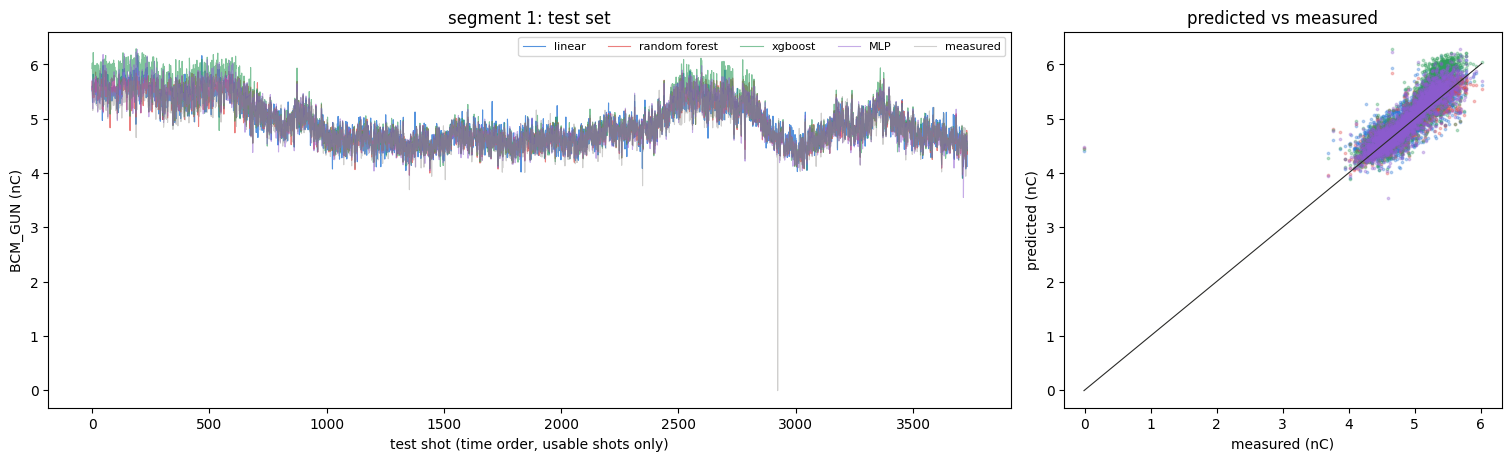

In [8]:
display(pd.DataFrame(results).T.round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]}, layout="constrained")
shots = np.arange(len(y_test))
for ii, (name, color) in enumerate( [("linear", "#2a78d6"), ("random forest", "#e34948"), ("xgboost", "#2e9e5b"), ("MLP", "#8e5bd0")] ):
    ax1.plot(shots, predictions[name], color=color, lw=0.8, alpha=0.8-ii*0.1, label=name)
    ax2.scatter(y_test, predictions[name], s=3, color=color, alpha=0.3, label=name)
ax1.plot(shots, y_test.to_numpy(), color="#8a8985", alpha=0.4, lw=0.8, label="measured")
lim = [y_test.min(), y_test.max()]
ax2.plot(lim, lim, color="#2b2b29", lw=0.8)
ax1.set(xlabel="test shot (time order, usable shots only)", ylabel="BCM_GUN (nC)", title=f"segment {SEGMENT}: test set")
ax2.set(xlabel="measured (nC)", ylabel="predicted (nC)", title="predicted vs measured")
ax1.legend(fontsize=8, ncols=5)
plt.show()

## All segments

The same models, with the same settings as in the cells above (`clone` copies an estimator's settings, not
its fit), on every dataset, each with its own chronological split. The charge level differs a lot between segments
(~100 pC to ~10 000 pC), so compare the MAE within a row, or relative to `BCM mean`; R² is comparable across rows.
`BCM std` is the standard deviation of the test shots around their own mean (the square root of the variance,
so in pC like the MAE): a model whose MAE is not clearly below it does little better than knowing the test mean.
Best model per segment in bold. Segment 2 has only ~150 usable shots: its scores are noisy.

In [9]:
from sklearn.base import clone

# the three regimes of the clean data, as in 08_01 (results/data_labelling/stitched_bcm.png), by segment number
REGIMES = {"low charge": [0, 2, 3, 4], "high, repetitive": [5], "high, non-repetitive": [1, 6, 7]}
REGIME_OF = {s: r for r, segs in REGIMES.items() for s in segs}
MODELS = {"linear": linear, "random forest": forest, "xgboost": xgb, "MLP": mlp}   # fitted above: only their settings are reused
DETREND_K = 50     # detrended run only (section below): shots in the trailing mean, as SLOW in 08_01


def load(segment, detrend=False):
    """One dataset as in the load cell above -> train, test DataFrames with the FEATURES, the charge BCM_GUN, the
    target y the models learn and the base added back to their predictions (0 here; detrended: see below)."""
    d = np.load(DATASETS / f"segment_{segment:02d}.npz")
    df = pd.DataFrame(d["X"], columns=d["features"])
    df["lab_laser_power"] *= 1e6                                     # J -> µJ, see the load cell
    df["BCM_GUN"] = d["y"]
    df["base"] = 0.0
    if detrend:                                                      # minus the mean of the previous DETREND_K shots
        trailing = lambda v: v.shift(1).rolling(DETREND_K, min_periods=5).mean()
        df["base"] = trailing(df["BCM_GUN"])
        df[FEATURES] -= df[FEATURES].apply(trailing)
    df["y"] = df["BCM_GUN"] - df["base"]
    df["test"] = np.arange(len(df)) >= int(len(df) * (1 - TEST_FRAC))
    use = df[d["valid"] & df[FEATURES + ["base"]].notna().all(axis=1).to_numpy()]
    return use[~use["test"]], use[use["test"]]


def evaluate(detrend=False, reference="train mean"):
    """MODELS on every segment -> summary table, curves; reference: name of the base + training-mean model."""
    rows, curves = [], {}
    for info in manifest["segments"]:
        k = info["segment"]
        tr, te = load(k, detrend)
        preds = {reference: te["base"] + tr["y"].mean()}
        for name, template in MODELS.items():
            model = clone(template)
            if name == "xgboost":                                     # early stopping on the end of the training part
                c = int(len(tr) * 0.8)
                model.fit(tr[FEATURES][:c], tr["y"][:c], eval_set=[(tr[FEATURES][c:], tr["y"][c:])], verbose=False)
            else:
                model.fit(tr[FEATURES], tr["y"])
            preds[name] = te["base"] + model.predict(te[FEATURES])
        y = te["BCM_GUN"]
        row = {("", "regime"): REGIME_OF[k], ("", "train"): len(tr), ("", "test"): len(te),
               ("", "BCM mean (pC)"): 1000 * y.mean(), ("", "BCM std (pC)"): 1000 * y.std()}
        for name, p in preds.items():
            row[("MAE (pC)", name)] = 1000 * mean_absolute_error(y, p)
            row[("R2", name)] = r2_score(y, p)
        rows.append(pd.Series(row, name=k))
        curves[k] = (y.to_numpy(), {name: np.asarray(p) for name, p in preds.items()})
        print(f"segment {k} done")
    summary = pd.DataFrame(rows).rename_axis("segment")
    summary.columns = pd.MultiIndex.from_tuples(summary.columns)
    summary = summary[[c for c in summary.columns if c[0] == ""] + [c for c in summary.columns if c[0] == "MAE (pC)"]
                      + [c for c in summary.columns if c[0] == "R2"]]
    return summary, curves


def show(summary):
    mae, r2 = summary["MAE (pC)"].columns, summary["R2"].columns
    return (summary.style
        .format("{:.0f}", subset=[("", "train"), ("", "test")])
        .format("{:.0f}", subset=[("", "BCM mean (pC)")])
        .format("{:.1f}", subset=[("", "BCM std (pC)")])
        .format("{:.1f}", subset=[("MAE (pC)", m) for m in mae])
        .format("{:.3f}", subset=[("R2", m) for m in r2])
        .highlight_min(subset=[("MAE (pC)", m) for m in mae], axis=1, props="font-weight: bold")
        .highlight_max(subset=[("R2", m) for m in r2], axis=1, props="font-weight: bold"))


summary, curves = evaluate()
show(summary)

segment 0 done
segment 1 done
segment 2 done
segment 3 done
segment 4 done
segment 5 done
segment 6 done
segment 7 done


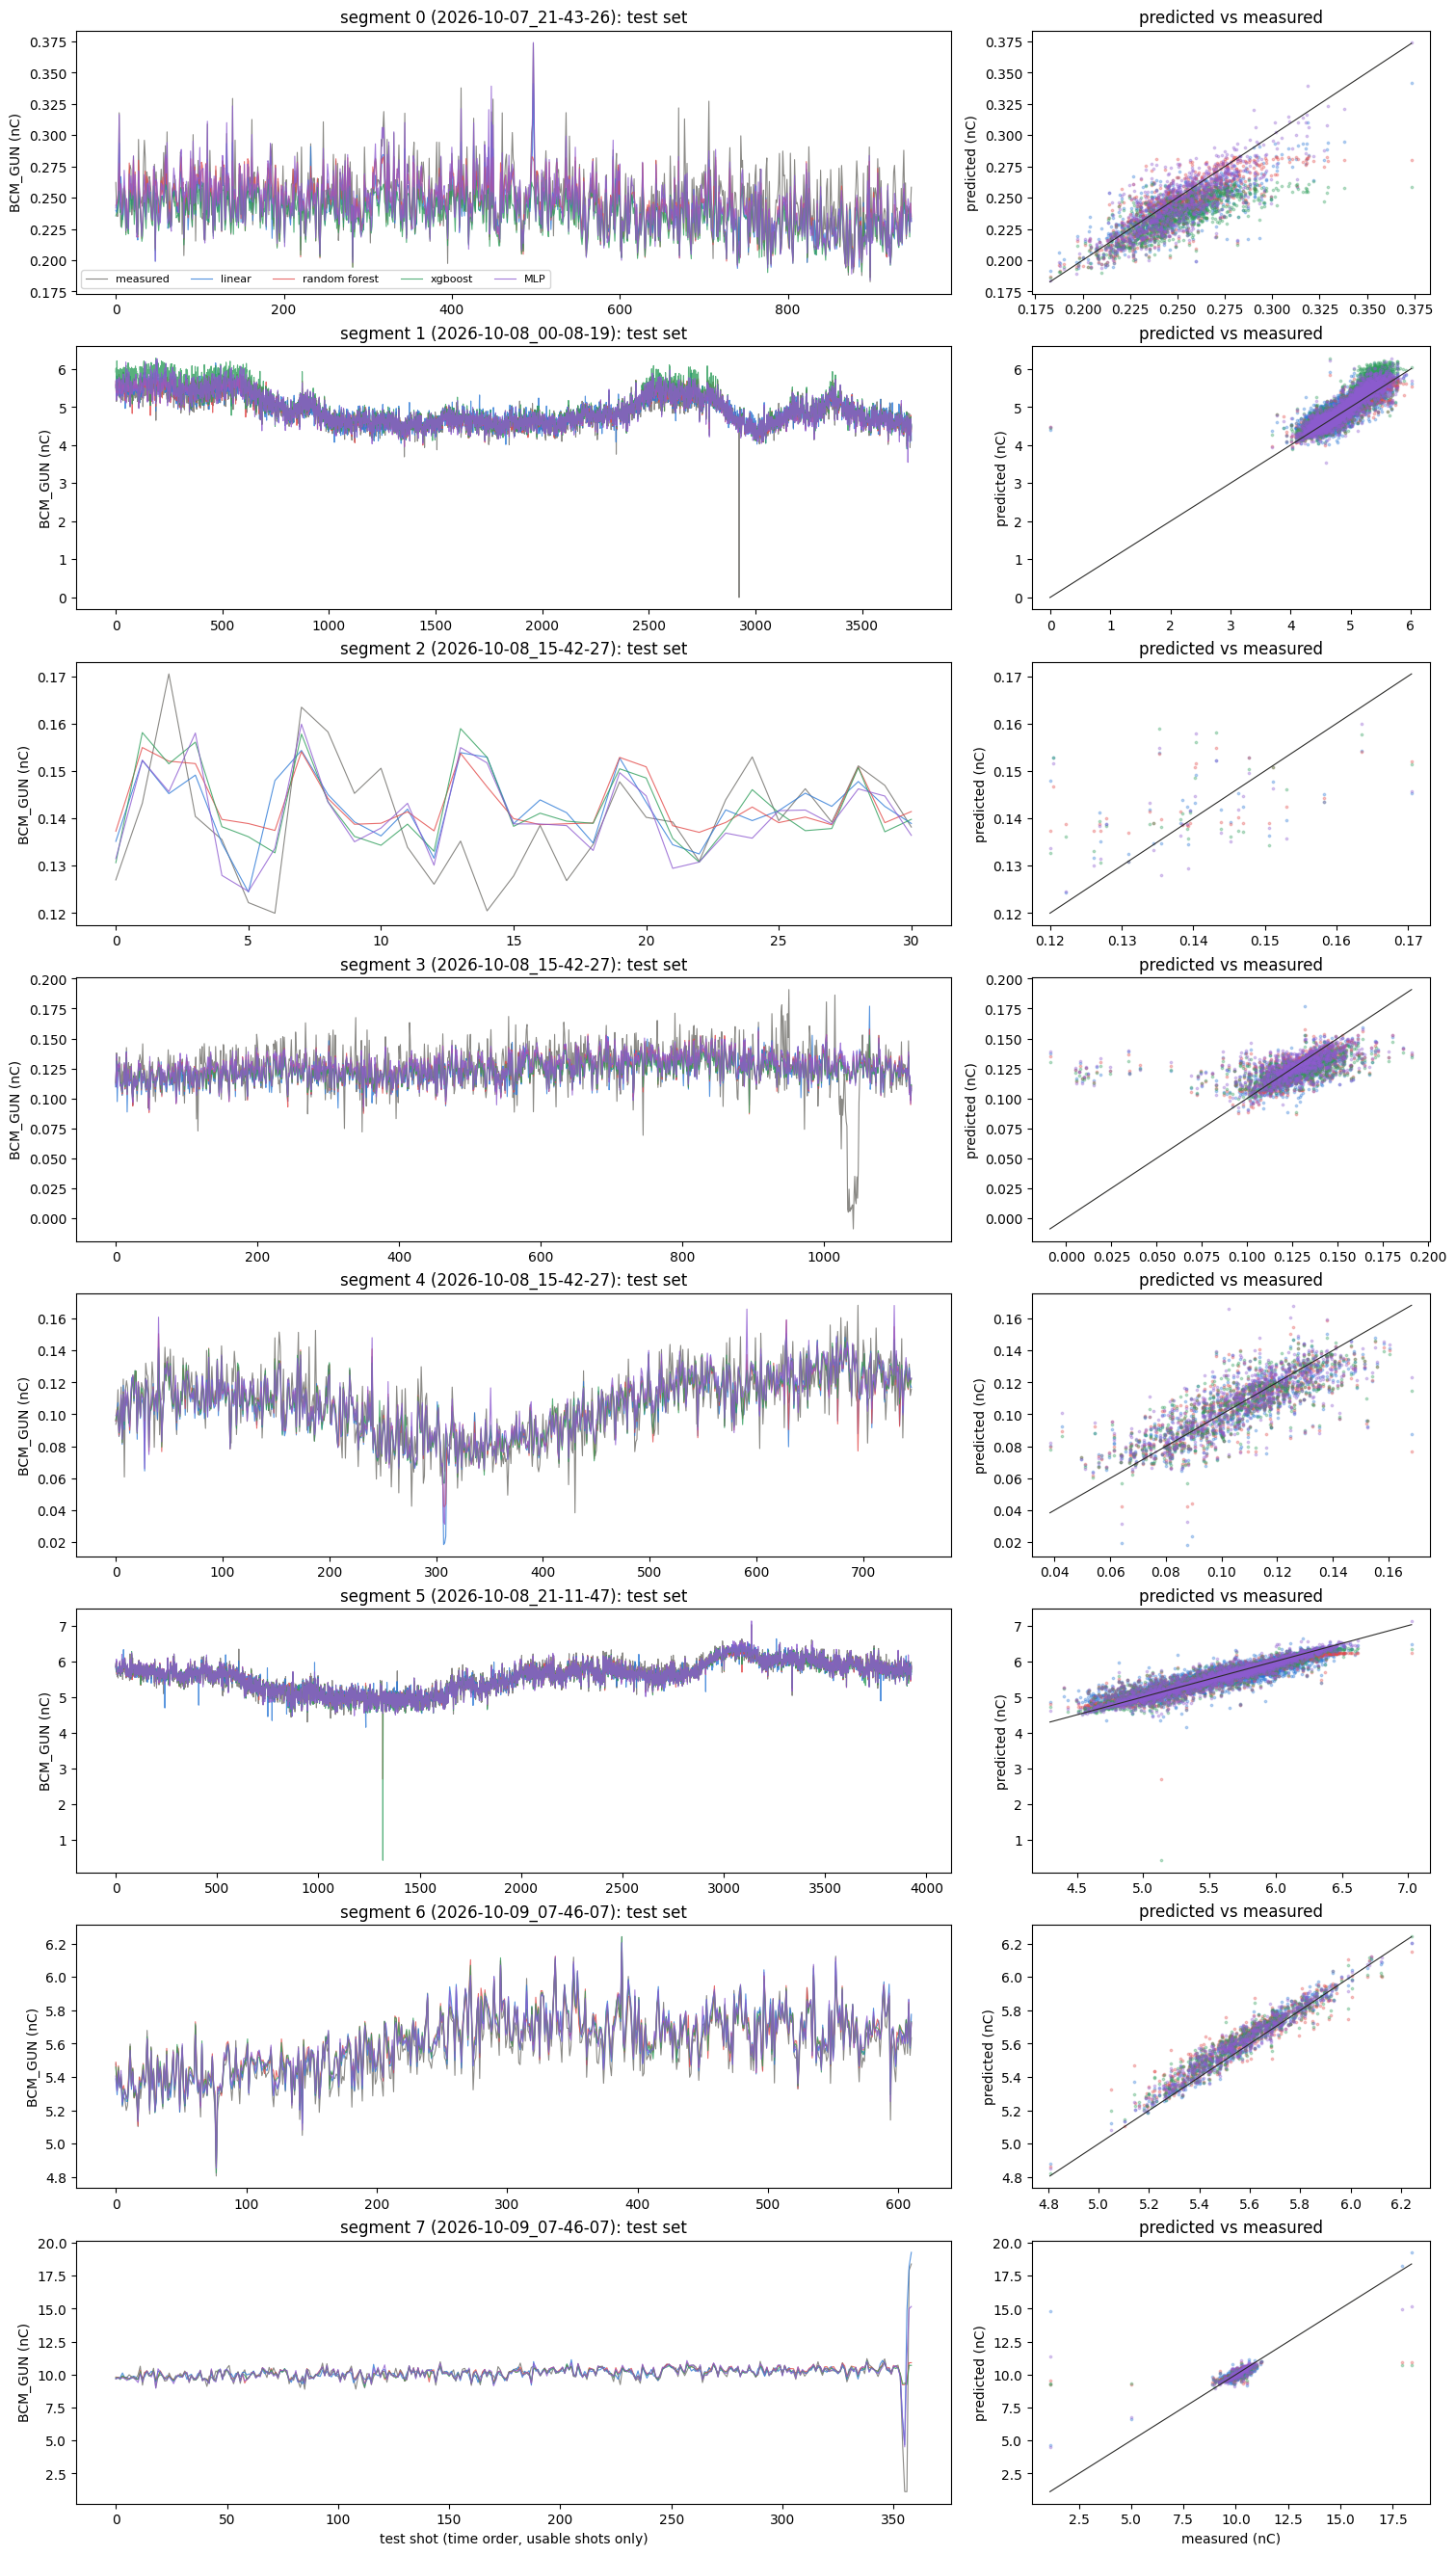

In [10]:
COLORS = {"linear": "#2a78d6", "random forest": "#e34948", "xgboost": "#2e9e5b", "MLP": "#8e5bd0"}


def plot(curves, label=""):
    fig, axes = plt.subplots(len(curves), 2, figsize=(15, 3.3 * len(curves)), gridspec_kw={"width_ratios": [2.2, 1]},
                             layout="constrained", squeeze=False)
    for (ax1, ax2), (k, (y, preds)) in zip(axes, curves.items()):
        shots = np.arange(len(y))
        ax1.plot(shots, y, color="#8a8985", lw=0.8, label="measured")
        for name, color in COLORS.items():
            ax1.plot(shots, preds[name], color=color, lw=0.8, alpha=0.8, label=name)
            ax2.scatter(y, preds[name], s=3, color=color, alpha=0.3)
        ax2.plot([y.min(), y.max()], [y.min(), y.max()], color="#2b2b29", lw=0.8)
        run = manifest["segments"][k]["run"].removeprefix("acquisition_")
        ax1.set(ylabel="BCM_GUN (nC)", title=f"segment {k} ({run}): test set{label}")
        ax2.set(ylabel="predicted (nC)", title="predicted vs measured")
    axes[0, 0].legend(fontsize=8, ncols=5)
    axes[-1, 0].set_xlabel("test shot (time order, usable shots only)")
    axes[-1, 1].set_xlabel("measured (nC)")
    plt.show()


plot(curves)

## Detrended

**What the models above get:** raw values, no detrending. Normalisation only where a model needs it: the linear
model and the MLP standardise their inputs (the MLP also its target); the trees do not care about scale. So all of
them have to learn the slow drift of the charge from the features too.

**Here:** every feature and the BCM minus the mean of its own previous `DETREND_K` readings in the segment
(**causal**: only past shots; a centred mean, as in 07_02, would use future shots that a real-time estimate does
not have). The models learn the BCM's deviation from its trailing level from the features' deviations from
theirs; the prediction is trailing level + predicted deviation, so the MAE in pC compares directly with the table
above (same test shots).

- **Different use case:** the trailing level needs the BCM readings up to the previous shot. This is "the BCM worked
  until the last shot, estimate this one", as in 08_01, not a stand-alone virtual BCM.
- **Reference:** `trailing mean` = the trailing level alone (+ the mean training deviation, ≈ 0).
- The level is additive here (nC). 08_01 does the same in logs (relative jitter) and adds sequence models.
- Shots where the BCM briefly read ~0 (e.g. ~70 on segment 5) are not removed here, unlike 08_01: they pull the
  trailing level down for the next `DETREND_K` shots.

In [11]:
summary_dt, curves_dt = evaluate(detrend=True, reference="trailing mean")
show(summary_dt)

segment 0 done
segment 1 done
segment 2 done
segment 3 done
segment 4 done
segment 5 done
segment 6 done
segment 7 done


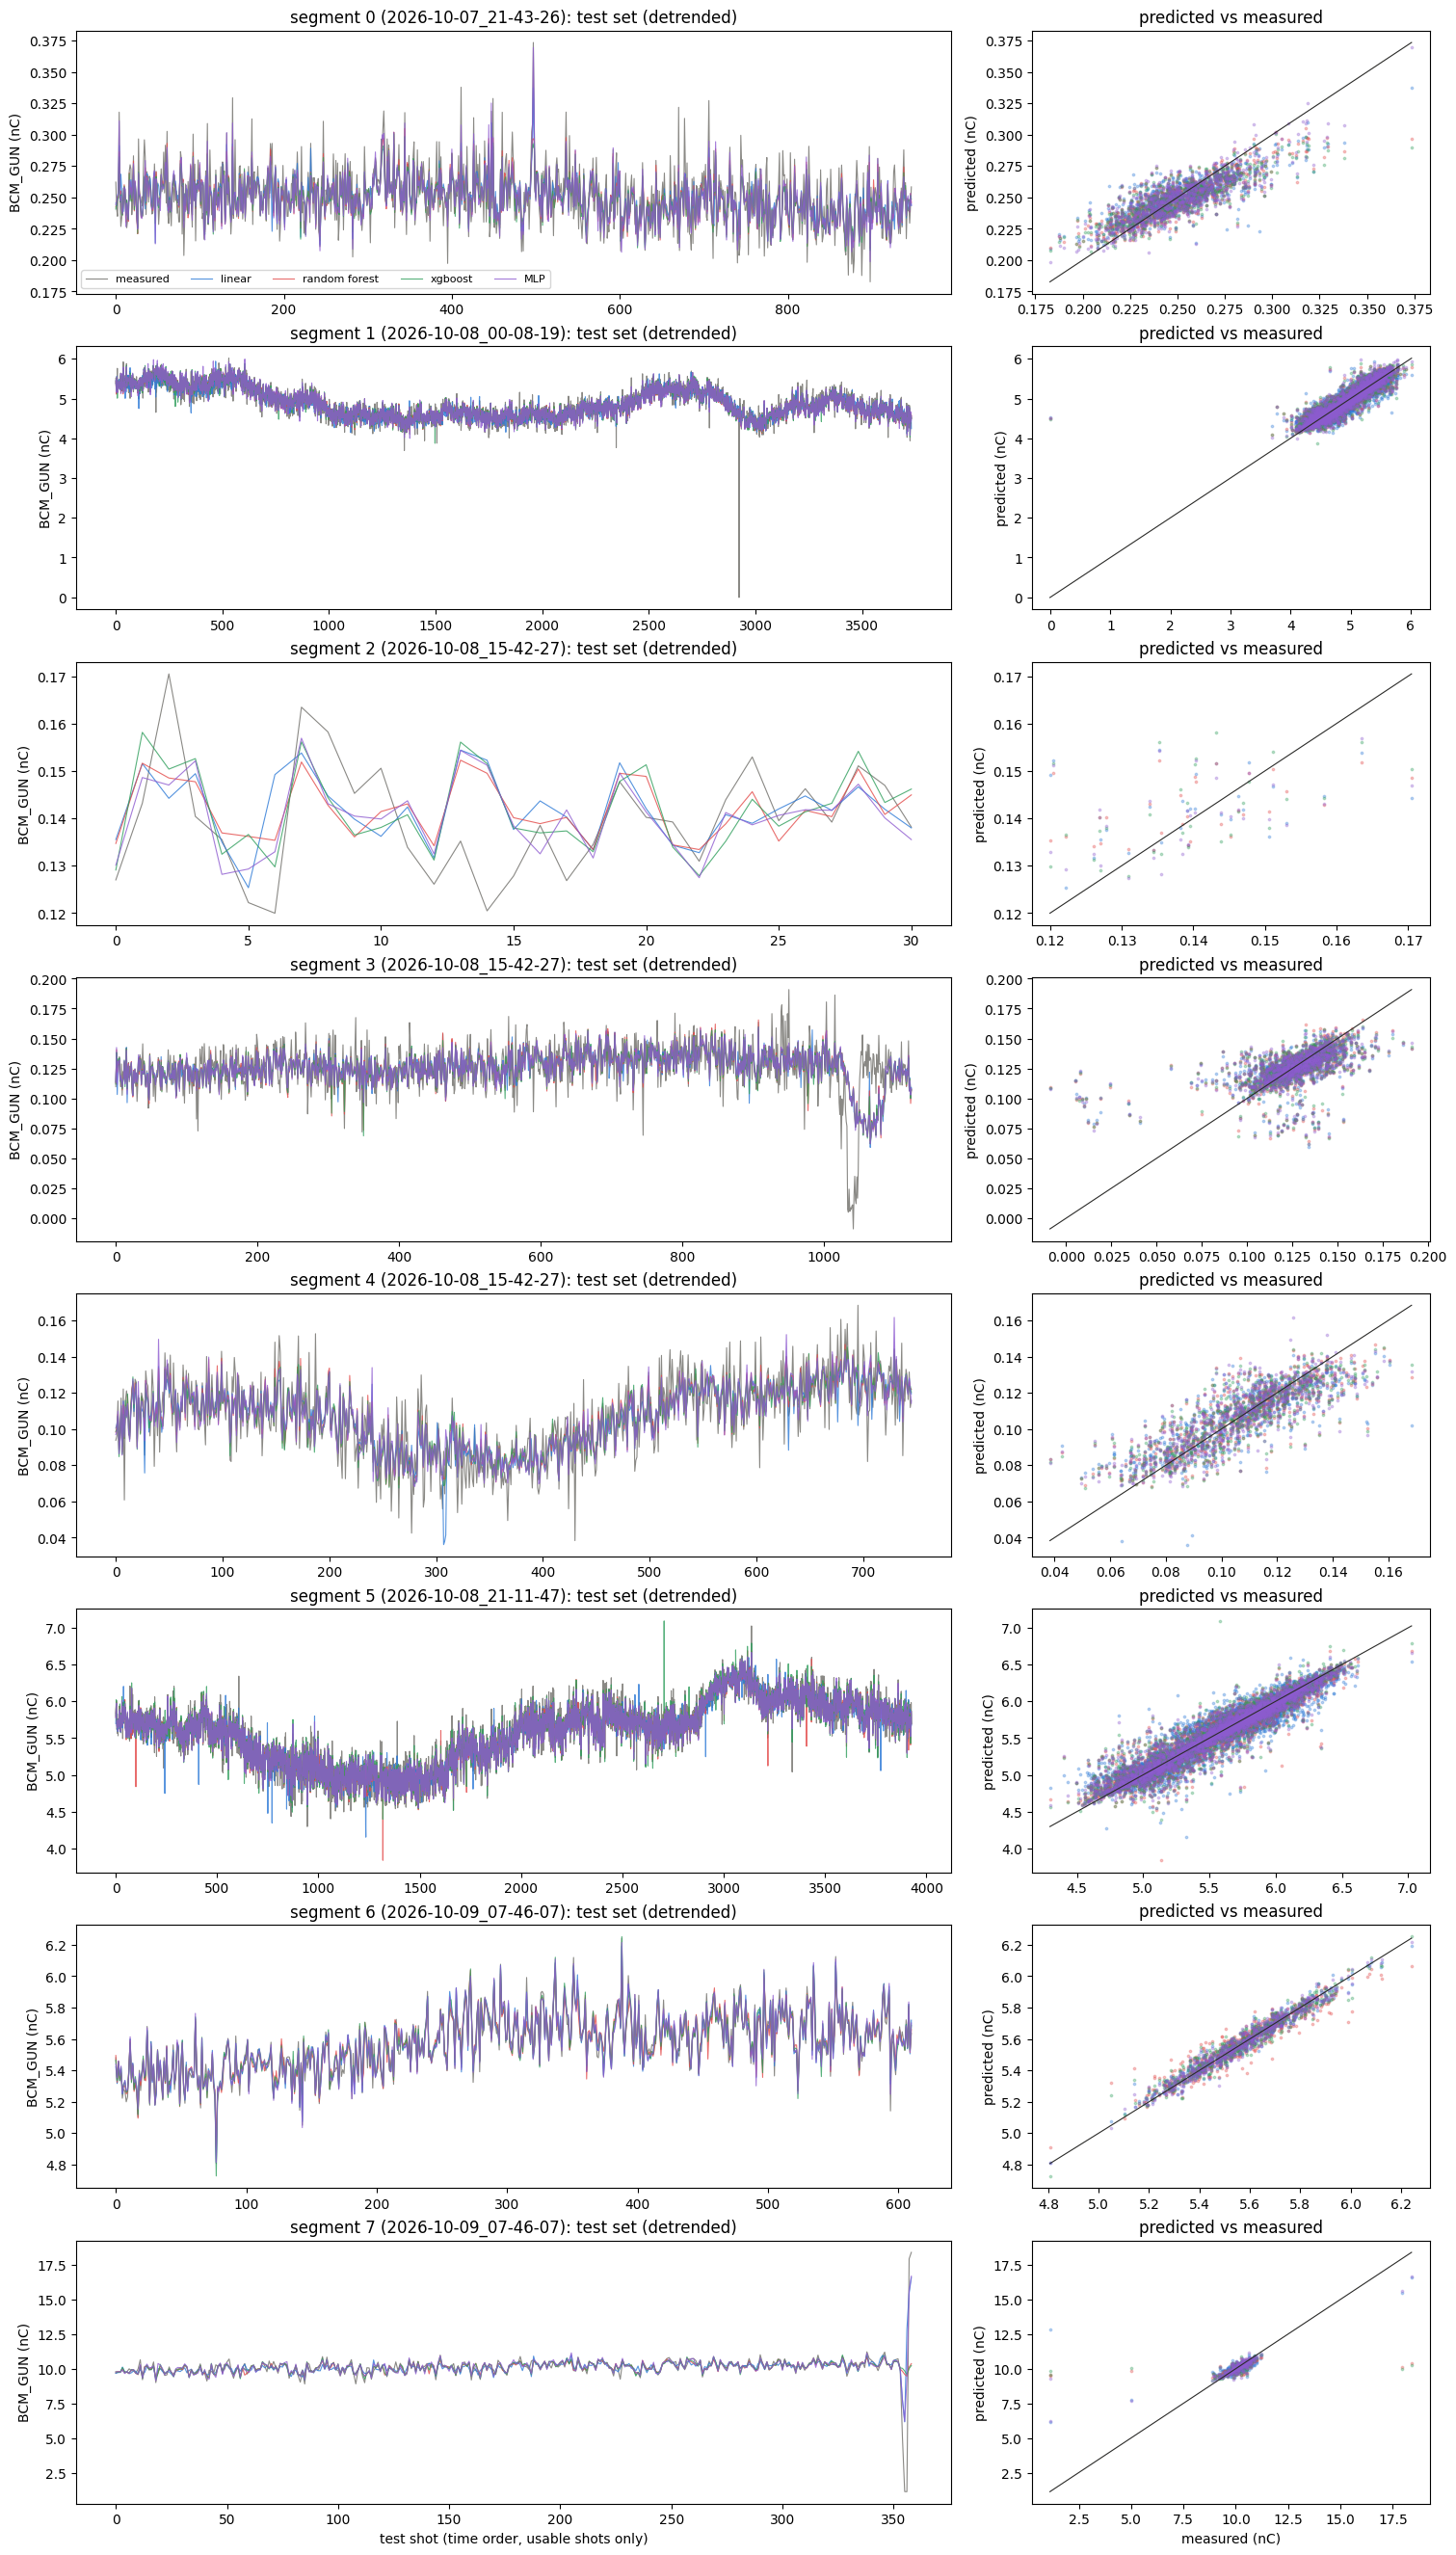

In [12]:
plot(curves_dt, " (detrended)")

MAE (pC) of both runs side by side, best per segment in bold.

In [13]:
both = pd.concat({"raw": summary["MAE (pC)"], "detrended": summary_dt["MAE (pC)"]}, axis=1)
both.insert(0, ("", "BCM std (pC)"), summary[("", "BCM std (pC)")])
both.insert(0, ("", "regime"), summary[("", "regime")])
both.style.format("{:.1f}", subset=both.columns[1:]).highlight_min(subset=both.columns[2:], axis=1, props="font-weight: bold")